# 财务舞弊风险检测 — 实验笔记本

**项目说明**：基于上市公司财务报表数据，构建 XGBoost 模型识别财务舞弊风险。  
**规则 A**：所有预处理（填充、标准化）均在 Pipeline 内部完成，不在全局做 fillna / fit_transform，杜绝数据泄露。  
**免责声明**：模型输出仅为风险预警，不能直接定性财务舞弊。

## 0. 环境准备

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, LeaveOneOut, cross_validate
from sklearn.metrics import (roc_curve, auc, confusion_matrix, classification_report,
                             accuracy_score, precision_score, recall_score, roc_auc_score)
from sklearn.linear_model import LogisticRegression
import xgboost as xgb
import shap
import joblib
import os

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

PROJECT_DIR = r'C:\Users\季天源\Desktop\智算'
DATA_FILE = os.path.join(PROJECT_DIR, 'fraud_data.csv', 'fraud_data.csv')
print('依赖加载完成')

依赖加载完成


## 1. 数据加载与初步探索

In [2]:
# 1.1 读取数据集
df = pd.read_csv(DATA_FILE)
print(f'数据集形状: {df.shape}')
print(f'\n列名:\n{df.columns.tolist()}')

数据集形状: (100, 36)

列名:
['货币资金', '应收账款净额', '存货净额', '流动资产合计', '固定资产净额', '商誉净额', '资产总计', '流动负债合计', '负债合计', '实收资本(或股本)', '盈余公积', '未分配利润', '所有者权益合计', '营业总收入', '营业成本', '销售费用', '管理费用', '财务费用', '投资收益', '资产减值损失', '营业利润', '利润总额', '减：所得税费用', '净利润', '归属于母公司所有者的净利润', '经营活动产生的现金流量净额', '支付的各项税费', '销售商品、提供劳务收到的现金', '投资活动产生的现金流量净额', '筹资活动产生的现金流量净额', '商誉缺失标记', '被ST', '舞弊处罚', '金融业', '恒等式偏差', 'label']


In [3]:
# 1.2 拆分特征和标签
y = df['label']
X_raw = df.drop(columns=['label'])
print(f'特征维度: {X_raw.shape}')
print(f'标签分布:\n{y.value_counts()}')
print(f'\n正样本比例: {y.mean():.2%}')

特征维度: (100, 35)
标签分布:
label
0    60
1    40
Name: count, dtype: int64

正样本比例: 40.00%


In [4]:
# 1.3 查看空值统计（仅查看，不做全局填充）
null_stats = X_raw.isnull().sum()
null_stats = null_stats[null_stats > 0].sort_values(ascending=False)
print(f'存在空值的特征数: {len(null_stats)}')
print(f'\n空值统计:\n{null_stats}')
print(f'\n各列数据类型:\n{X_raw.dtypes.value_counts()}')

存在空值的特征数: 10

空值统计:
资产减值损失            6
投资收益              5
销售费用              4
减：所得税费用           4
营业成本              2
应收账款净额            1
存货净额              1
盈余公积              1
财务费用              1
销售商品、提供劳务收到的现金    1
dtype: int64

各列数据类型:
float64    31
int64       4
Name: count, dtype: int64


findfont: Failed to find font weight bold for SimHei, now using 400.


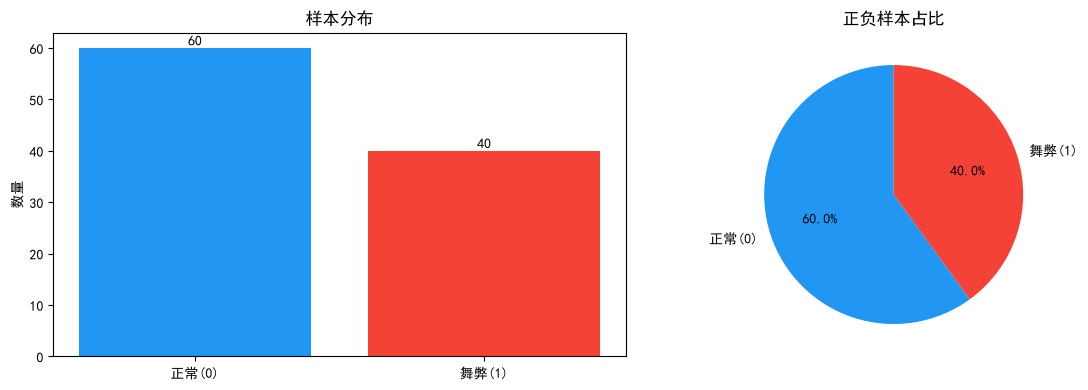

正负样本比例约 40:60，存在一定不平衡


In [5]:
# 1.4 标签分布可视化
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(['正常(0)', '舞弊(1)'], y.value_counts().values, color=['#2196F3', '#F44336'])
axes[0].set_title('样本分布')
axes[0].set_ylabel('数量')
for i, v in enumerate(y.value_counts().values):
    axes[0].text(i, v + 0.5, str(v), ha='center', fontweight='bold')

axes[1].pie(y.value_counts().values, labels=['正常(0)', '舞弊(1)'],
            colors=['#2196F3', '#F44336'], autopct='%1.1f%%', startangle=90)
axes[1].set_title('正负样本占比')
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, 'label_distribution.png'), dpi=150, bbox_inches='tight')
plt.show()
print('正负样本比例约 40:60，存在一定不平衡')

## 2. 特征工程

### 2.1 第一步：剔除高共线性特征
计算 Pearson 相关系数矩阵，两两特征相关系数 > 0.8 时，保留与标签 y 相关性更高的特征。

In [6]:
# 2.1.1 计算相关系数矩阵
corr_matrix = X_raw.corr(method='pearson')
label_corr = X_raw.corrwith(y, method='pearson').abs()

print('各特征与标签的绝对相关系数 (Top 15):')
print(label_corr.sort_values(ascending=False).head(15))

各特征与标签的绝对相关系数 (Top 15):
被ST              0.291343
舞弊处罚             0.228234
商誉缺失标记           0.201859
财务费用             0.192283
恒等式偏差            0.190356
销售费用             0.152698
未分配利润            0.140340
投资收益             0.127230
营业总收入            0.118812
筹资活动产生的现金流量净额    0.118246
所有者权益合计          0.111635
支付的各项税费          0.104307
货币资金             0.101331
固定资产净额           0.099912
净利润              0.099241
dtype: float64


In [7]:
# 2.1.2 共线性过滤
dropped_features = set()
features = X_raw.columns.tolist()

for i in range(len(features)):
    for j in range(i + 1, len(features)):
        if features[i] in dropped_features or features[j] in dropped_features:
            continue
        if abs(corr_matrix.loc[features[i], features[j]]) > 0.8:
            corr_i = label_corr.get(features[i], 0)
            corr_j = label_corr.get(features[j], 0)
            if corr_i >= corr_j:
                dropped_features.add(features[j])
            else:
                dropped_features.add(features[i])

print(f'原始特征数: {len(features)}')
print(f'因共线性剔除的特征数: {len(dropped_features)}')
print(f'剔除的特征: {list(dropped_features)}')

collinear_filtered_features = [f for f in features if f not in dropped_features]
print(f'\n共线性过滤后特征数: {len(collinear_filtered_features)}')
print(f'保留特征: {collinear_filtered_features}')

原始特征数: 35
因共线性剔除的特征数: 25
剔除的特征: ['负债合计', '流动资产合计', '所有者权益合计', '资产总计', '货币资金', '减：所得税费用', '固定资产净额', '实收资本(或股本)', '管理费用', '营业成本', '流动负债合计', '销售商品、提供劳务收到的现金', '盈余公积', '资产减值损失', '投资活动产生的现金流量净额', '营业总收入', '存货净额', '经营活动产生的现金流量净额', '商誉净额', '归属于母公司所有者的净利润', '支付的各项税费', '应收账款净额', '营业利润', '利润总额', '净利润']

共线性过滤后特征数: 10
保留特征: ['未分配利润', '销售费用', '财务费用', '投资收益', '筹资活动产生的现金流量净额', '商誉缺失标记', '被ST', '舞弊处罚', '金融业', '恒等式偏差']


In [8]:
# 2.1.3 共线性热力图
plt.figure(figsize=(16, 12))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix.loc[collinear_filtered_features, collinear_filtered_features],
            mask=mask, cmap='RdBu_r', center=0, annot=False,
            fmt='.2f', square=True, linewidths=0.5)
plt.title('共线性过滤后特征相关系数矩阵', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, 'correlation_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

ValueError: Mask must have the same shape as data.

<Figure size 1600x1200 with 0 Axes>

### 2.2 第二步：筛选 10-15 个核心特征

**方案 1**：LASSO 逻辑回归筛选系数非零特征  
**方案 2**：XGBoost 特征重要性 Top 10-15  
**取两套方法结果交集**

In [ ]:
# 方案 1: LASSO 逻辑回归
X_filtered = X_raw[collinear_filtered_features].copy()

# 临时填充空值用于特征选择（不影响最终 Pipeline）
X_temp = X_filtered.fillna(X_filtered.median())
scaler_temp = StandardScaler()
X_scaled_temp = scaler_temp.fit_transform(X_temp)

# 调节 C 值使特征数在 10-15 范围
best_C = None
best_n = 0
for C_val in [0.001, 0.005, 0.01, 0.05, 0.1, 0.5, 1.0, 5.0, 10.0]:
    lasso = LogisticRegression(penalty='l1', C=C_val, solver='liblinear',
                                max_iter=10000, random_state=42)
    lasso.fit(X_scaled_temp, y)
    n_nonzero = np.sum(lasso.coef_ != 0)
    print(f'C={C_val:.3f}, 非零系数特征数={n_nonzero}')
    if 10 <= n_nonzero <= 15:
        best_C = C_val
        best_n = n_nonzero
        break
    elif n_nonzero < 10:
        best_C = C_val
        best_n = n_nonzero

if best_C is None:
    best_C = 0.01

lasso_final = LogisticRegression(penalty='l1', C=best_C, solver='liblinear',
                                  max_iter=10000, random_state=42)
lasso_final.fit(X_scaled_temp, y)
lasso_features = [collinear_filtered_features[i] for i in range(len(collinear_filtered_features))
                   if lasso_final.coef_[0][i] != 0]

print(f'\nLASSO 最终参数 C={best_C}')
print(f'LASSO 筛选特征 ({len(lasso_features)} 个): {lasso_features}')

In [ ]:
# 方案 2: XGBoost 特征重要性
xgb_temp = xgb.XGBClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.1,
    scale_pos_weight=len(y[y == 0]) / max(len(y[y == 1]), 1),
    random_state=42, use_label_encoder=False, eval_metric='logloss'
)
xgb_temp.fit(X_scaled_temp, y)

importance = pd.Series(xgb_temp.feature_importances_, index=collinear_filtered_features)
importance = importance.sort_values(ascending=False)

# 取 Top 15
xgb_top_features = importance.head(15).index.tolist()
print(f'XGBoost 特征重要性 Top 15:')
print(importance.head(15))
print(f'\nXGBoost 筛选特征 ({len(xgb_top_features)} 个): {xgb_top_features}')

In [ ]:
# 取交集
intersection_features = list(set(lasso_features) & set(xgb_top_features))
print(f'LASSO 特征数: {len(lasso_features)}')
print(f'XGBoost Top15 特征数: {len(xgb_top_features)}')
print(f'交集特征数: {len(intersection_features)}')
print(f'交集特征: {intersection_features}')

# 如果交集不足 10 个，补充 XGBoost 排名靠前但不在交集中的特征
if len(intersection_features) < 10:
    print(f'\n交集不足 10 个，从 XGBoost Top15 补充...')
    for f in xgb_top_features:
        if f not in intersection_features:
            intersection_features.append(f)
        if len(intersection_features) >= 12:
            break

# 如果交集超过 15 个，按 XGBoost 重要性截取
if len(intersection_features) > 15:
    ranked = importance[importance.index.isin(intersection_features)].head(15)
    intersection_features = ranked.index.tolist()

final_features = intersection_features
print(f'\n=== 最终建模特征 ({len(final_features)} 个) ===')
for i, f in enumerate(final_features, 1):
    print(f'  {i}. {f}')

# 生成 X_final
X_final = X_raw[final_features].copy()
print(f'\nX_final 形状: {X_final.shape}')

In [ ]:
# 特征重要性可视化
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# LASSO 系数
lasso_coef = pd.Series(lasso_final.coef_[0], index=collinear_filtered_features)
lasso_coef_nz = lasso_coef[lasso_coef != 0].sort_values()
colors_lasso = ['#F44336' if v > 0 else '#2196F3' for v in lasso_coef_nz.values]
lasso_coef_nz.plot(kind='barh', ax=axes[0], color=colors_lasso)
axes[0].set_title(f'LASSO 回归系数 (C={best_C})', fontsize=12)
axes[0].set_xlabel('系数值')
axes[0].axvline(x=0, color='black', linewidth=0.8)

# XGBoost 重要性
importance.head(15).sort_values().plot(kind='barh', ax=axes[1], color='#FF9800')
axes[1].set_title('XGBoost 特征重要性 Top 15', fontsize=12)
axes[1].set_xlabel('重要性')

plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, 'feature_importance.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. 模型训练与交叉验证

### 3.1 构建 Pipeline 流水线
预处理全部在 Pipeline 内部完成，杜绝数据泄露。

In [ ]:
# 3.1.1 构建 Pipeline
scale_pos_weight = len(y[y == 0]) / max(len(y[y == 1]), 1)
print(f'scale_pos_weight: {scale_pos_weight:.2f}')

pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('classifier', xgb.XGBClassifier(
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        min_child_weight=3,
        gamma=0.1,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        use_label_encoder=False,
        eval_metric='logloss'
    ))
])

print(f'\nPipeline 结构:')
print(pipeline)

### 3.2 分层 5 折交叉验证

In [ ]:
# 3.2.1 执行分层 5 折交叉验证
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'auc': 'roc_auc',
    'f1': 'f1'
}

cv_results = cross_validate(
    pipeline, X_final, y,
    cv=cv,
    scoring=scoring,
    return_estimator=True,
    return_train_score=False
)

print('=== 分层 5 折交叉验证结果 ===')
metrics_df = pd.DataFrame({
    'Accuracy': cv_results['test_accuracy'],
    'Precision': cv_results['test_precision'],
    'Recall': cv_results['test_recall'],
    'AUC-ROC': cv_results['test_auc'],
    'F1': cv_results['test_f1']
})
metrics_df.index = [f'Fold {i+1}' for i in range(5)]
metrics_df.loc['Mean'] = metrics_df.mean()
metrics_df.loc['Std'] = metrics_df.std()
print(metrics_df.round(4))

In [ ]:
# 3.2.2 收集每折预测结果，绘制 ROC 曲线
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# ROC 曲线
tprs = []
aucs = []
mean_fpr = np.linspace(0, 1, 100)

for i, (train_idx, test_idx) in enumerate(cv.split(X_final, y)):
    estimator = cv_results['estimator'][i]
    X_test_fold = X_final.iloc[test_idx]
    y_test_fold = y.iloc[test_idx]
    
    y_prob = estimator.predict_proba(X_test_fold)[:, 1]
    fpr, tpr, _ = roc_curve(y_test_fold, y_prob)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    
    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)
    
    axes[0].plot(fpr, tpr, lw=2, alpha=0.6,
                label=f'Fold {i+1} (AUC = {roc_auc:.3f})')

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = auc(mean_fpr, mean_tpr)
axes[0].plot(mean_fpr, mean_tpr, color='navy', lw=3, linestyle='--',
            label=f'平均 ROC (AUC = {mean_auc:.3f})')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5)
axes[0].set_xlabel('假阳性率 (FPR)', fontsize=12)
axes[0].set_ylabel('真阳性率 (TPR)', fontsize=12)
axes[0].set_title('5 折交叉验证 ROC 曲线', fontsize=14)
axes[0].legend(loc='lower right', fontsize=9)
axes[0].grid(True, alpha=0.3)

# 混淆矩阵（汇总所有折）
all_y_pred = np.zeros(len(y))
all_y_true = np.zeros(len(y))
for i, (train_idx, test_idx) in enumerate(cv.split(X_final, y)):
    estimator = cv_results['estimator'][i]
    X_test_fold = X_final.iloc[test_idx]
    y_test_fold = y.iloc[test_idx]
    y_pred_fold = estimator.predict(X_test_fold)
    all_y_pred[test_idx] = y_pred_fold
    all_y_true[test_idx] = y_test_fold

cm = confusion_matrix(all_y_true, all_y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['正常(0)', '舞弊(1)'],
            yticklabels=['正常(0)', '舞弊(1)'])
axes[1].set_xlabel('预测标签', fontsize=12)
axes[1].set_ylabel('真实标签', fontsize=12)
axes[1].set_title('5 折交叉验证汇总混淆矩阵', fontsize=14)

plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, 'roc_confusion_matrix.png'), dpi=150, bbox_inches='tight')
plt.show()

print(f'\n汇总分类报告:\n{classification_report(all_y_true, all_y_pred, target_names=["正常(0)", "舞弊(1)"])}')

### 3.3 留一法交叉验证 (LOOCV) — 补充参考

In [ ]:
# LOOCV
loocv = LeaveOneOut()

loocv_results = cross_validate(
    pipeline, X_final, y,
    cv=loocv,
    scoring=scoring,
    return_estimator=False
)

print('=== 留一法交叉验证 (LOOCV) 结果 ===')
print(f'Accuracy:  {loocv_results["test_accuracy"].mean():.4f} ± {loocv_results["test_accuracy"].std():.4f}')
print(f'Precision: {loocv_results["test_precision"].mean():.4f} ± {loocv_results["test_precision"].std():.4f}')
print(f'Recall:    {loocv_results["test_recall"].mean():.4f} ± {loocv_results["test_recall"].std():.4f}')
print(f'AUC-ROC:   {loocv_results["test_auc"].mean():.4f} ± {loocv_results["test_auc"].std():.4f}')
print(f'F1:        {loocv_results["test_f1"].mean():.4f} ± {loocv_results["test_f1"].std():.4f}')

### 3.4 全量数据训练最终模型并保存

In [ ]:
# 3.4.1 全量训练
pipeline.fit(X_final, y)

# 全量训练评估
y_pred_full = pipeline.predict(X_final)
y_prob_full = pipeline.predict_proba(X_final)[:, 1]

print('=== 全量训练结果（仅供参考，存在过拟合风险）===')
print(f'Accuracy:  {accuracy_score(y, y_pred_full):.4f}')
print(f'Precision: {precision_score(y, y_pred_full):.4f}')
print(f'Recall:    {recall_score(y, y_pred_full):.4f}')
print(f'AUC-ROC:   {roc_auc_score(y, y_prob_full):.4f}')
print(f'\n混淆矩阵:')
print(confusion_matrix(y, y_pred_full))

# 3.4.2 保存 Pipeline 模型
model_path = os.path.join(PROJECT_DIR, 'model_pipeline.pkl')
joblib.dump(pipeline, model_path)
print(f'\n模型已保存到: {model_path}')

## 4. SHAP 可解释性分析

**规则 A 提醒**：离线画图可以用全集计算 SHAP；线上 API 推理必须对每个输入样本实时单独计算 SHAP。

In [ ]:
# 4.1 加载模型并提取 XGBoost 子模型
loaded_pipeline = joblib.load(model_path)
xgb_model = loaded_pipeline.named_steps['classifier']
imputer = loaded_pipeline.named_steps['imputer']
scaler = loaded_pipeline.named_steps['scaler']

# 4.2 预处理数据用于 SHAP 计算
X_final_processed = scaler.transform(imputer.transform(X_final))
X_processed_df = pd.DataFrame(X_final_processed, columns=final_features)

print(f'预处理后数据形状: {X_processed_df.shape}')
print(f'XGBoost 模型参数: max_depth={xgb_model.max_depth}, n_estimators={xgb_model.n_estimators}')

In [ ]:
# 4.3 实例化 TreeExplainer 并计算 SHAP 值
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_processed_df)

print(f'SHAP 值形状: {np.array(shap_values).shape}')
print(f'SHAP 值范围: [{np.array(shap_values).min():.4f}, {np.array(shap_values).max():.4f}]')

In [ ]:
# 4.4 SHAP Summary Plot (蜂群图)
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_processed_df, feature_names=final_features,
                  show=False, max_display=15)
plt.title('SHAP Feature Importance (Summary Plot)', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, 'shap_summary.png'), dpi=150, bbox_inches='tight')
plt.show()
print('SHAP 蜂群图已保存: shap_summary.png')

In [ ]:
# 4.5 SHAP 条形图
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_processed_df, feature_names=final_features,
                  plot_type='bar', show=False, max_display=15)
plt.title('SHAP Feature Importance (Bar Plot)', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(PROJECT_DIR, 'shap_bar.png'), dpi=150, bbox_inches='tight')
plt.show()
print('SHAP 条形图已保存: shap_bar.png')

In [ ]:
# 4.6 Force Plot 瀑布图 — 挑选 2 个真实舞弊样本 (y=1)
fraud_indices = y[y == 1].index.tolist()
print(f'舞弊样本索引: {fraud_indices[:5]}...')

# 选择前 2 个舞弊样本
sample_indices = fraud_indices[:2]

for idx in sample_indices:
    plt.figure(figsize=(20, 5))
    
    sample_shap = shap_values[idx]
    sample_features = X_processed_df.iloc[idx].values
    
    # 创建 Force Plot 并保存
    fig = shap.force_plot(
        explainer.expected_value,
        sample_shap,
        sample_features,
        feature_names=final_features,
        matplotlib=True,
        show=False
    )
    
    plt.title(f'SHAP Force Plot - 舞弊样本 #{idx} (真实标签: 1)', fontsize=14)
    plt.tight_layout()
    filename = f'force_plot_fraud_{idx}.png'
    plt.savefig(os.path.join(PROJECT_DIR, filename), dpi=150, bbox_inches='tight')
    plt.close()
    print(f'Force Plot 已保存: {filename}')

In [ ]:
# 4.7 使用 waterfall 图替代 force plot（更清晰的单样本解释）
for idx in sample_indices:
    plt.figure(figsize=(12, 6))
    
    explanation = shap.Explanation(
        values=shap_values[idx],
        base_values=explainer.expected_value,
        data=X_processed_df.iloc[idx].values,
        feature_names=final_features
    )
    
    shap.waterfall_plot(explanation, show=False, max_display=12)
    plt.title(f'SHAP 瀑布图 - 舞弊样本 #{idx}', fontsize=14)
    plt.tight_layout()
    filename = f'waterfall_plot_fraud_{idx}.png'
    plt.savefig(os.path.join(PROJECT_DIR, filename), dpi=150, bbox_inches='tight')
    plt.close()
    print(f'瀑布图已保存: {filename}')

In [ ]:
# 4.8 导出关键样本 SHAP 结果为 CSV
shap_result_rows = []
for idx in sample_indices:
    row = {'sample_index': idx, 'true_label': int(y.iloc[idx])}
    for j, feat in enumerate(final_features):
        row[f'{feat}_shap'] = shap_values[idx][j]
        row[f'{feat}_value'] = X_processed_df.iloc[idx][feat]
    row['base_value'] = explainer.expected_value
    row['prediction'] = y_prob_full[idx]
    shap_result_rows.append(row)

shap_df = pd.DataFrame(shap_result_rows)
shap_csv_path = os.path.join(PROJECT_DIR, 'shap_results_samples.csv')
shap_df.to_csv(shap_csv_path, index=False, encoding='utf-8-sig')
print(f'SHAP 结果已导出: {shap_csv_path}')
print(shap_df[['sample_index', 'true_label', 'base_value', 'prediction']].to_string())

## 5. 模型评估汇总

### 最终保留特征清单

In [ ]:
print('=' * 60)
print('最终建模特征清单')
print('=' * 60)
for i, f in enumerate(final_features, 1):
    lasso_mark = '✓' if f in lasso_features else ' '
    xgb_mark = '✓' if f in xgb_top_features else ' '
    print(f'  {i:2d}. {f:<30s} LASSO:{lasso_mark} XGB:{xgb_mark}')

print(f'\n特征总数: {len(final_features)}')
print(f'\n5 折 CV 平均指标:')
for metric in ['Accuracy', 'Precision', 'Recall', 'AUC-ROC', 'F1']:
    print(f'  {metric}: {metrics_df.loc["Mean", metric]:.4f} ± {metrics_df.loc["Std", metric]:.4f}')
print(f'\nLOOCV 平均指标:')
for metric in ['accuracy', 'precision', 'recall', 'auc', 'f1']:
    print(f'  {metric}: {loocv_results[f"test_{metric}"].mean():.4f} ± {loocv_results[f"test_{metric}"].std():.4f}')

print('\n⚠️ 免责声明：模型输出仅为风险预警，不能直接定性财务舞弊。')

## 6. 生成项目文件清单

In [ ]:
# 检查所有输出文件
expected_files = [
    'fraud_data.csv/fraud_data.csv',
    'model_pipeline.pkl',
    'shap_summary.png',
    'shap_bar.png',
    'roc_confusion_matrix.png',
    'feature_importance.png',
    'label_distribution.png',
    'correlation_matrix.png',
    'shap_results_samples.csv'
]

# 添加 force plot 和 waterfall plot
for idx in sample_indices:
    expected_files.append(f'force_plot_fraud_{idx}.png')
    expected_files.append(f'waterfall_plot_fraud_{idx}.png')

print('=== 项目输出文件检查 ===')
for f in expected_files:
    full_path = os.path.join(PROJECT_DIR, f)
    exists = os.path.exists(full_path)
    size = os.path.getsize(full_path) if exists else 0
    status = f'✓ ({size:,} bytes)' if exists else '✗ 缺失'
    print(f'  {status} {f}')